# KDD-BR 2018: Regression WiSARD e Kalman-ReW

Este é o dataset **original** da Regression WiSARD, o mesmo do artigo do ESANN
2019 e do Capítulo 5 da tese. Ele resolve três problemas que o House Prices
tinha:

**1. Os hiperparâmetros estão publicados.** A Tabela 1 do ESANN 2019 traz a
configuração da melhor ReW: `therm = 17, tw = 11, n = 17, simple mean`, com MAE
de 0.08737. Não precisamos escolher no escuro.

**2. A escala do alvo é conhecida e o número é comparável.** A produção foi
reescalada para $[0,1]$ pelos organizadores, para preservar o anonimato dos
valores reais mantendo a distribuição. Por isso o MAE de 0.09 da tese faz
sentido, e por isso o nosso número pode ser comparado ao dela diretamente,
coisa que era impossível no House Prices.

**3. Existe ordem temporal com deriva.** Os dados vão de 2004 a 2011, e a
produção média sobe ao longo dos anos. Isso importa porque o parâmetro $q$ do
filtro de Kalman só tem função quando a relação entre entrada e saída **muda ao
longo do tempo**. Nos experimentos anteriores, em tabela estática, ele não tinha
o que fazer.

**A métrica.** O Kaggle usa MAE simples:

$$
\text{MAE} = \frac{1}{n}\sum_{i=1}^{n}\bigl|\,\hat{y}_i - y_i\,\bigr|
$$

É a distância vertical média entre cada ponto e a reta $y = x$ num gráfico de
dispersão. Sem transformação, sem ponderação. Como o alvo está em $[0,1]$, o MAE
também está nessa escala.

In [35]:
import io, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": .25,
    "axes.spines.top": False, "axes.spines.right": False,
})

COR_REW = "#B4674D"     # ReW pura
COR_KAL = "#2F6B6A"     # Kalman-ReW
COR_REF = "#8A8F98"     # referências

# hiperparâmetros publicados na Tabela 1 do ESANN 2019 para a melhor ReW
ADDRESS_SIZE = 17       # n  = bits por RAM node
RESOLUTION   = 17       # therm = bits de thermometer por atributo
SEEDS = [0, 1, 2, 3, 4]

---
## 1. Os dados

Os arquivos vêm do repositório público da solução vencedora da competição
(`rafjaa/KDD-BR-2018`), que os distribui junto com o código. O `train.csv` tem
5243 linhas e o `test.csv` 4110, exatamente os números que a tese reporta.

O `test.csv` **não tem rótulo**, porque era o conjunto de submissão da
competição. Então, como no House Prices, montamos treino e teste a partir do
arquivo rotulado.

As colunas são: `field` (qual dos 28 campos), `age` (idade da palmeira),
`type` (variedade), `harvest_year` e `harvest_month`.

In [36]:
BASE = "https://raw.githubusercontent.com/rafjaa/KDD-BR-2018/master/data/"

def carrega(nome):
    with urllib.request.urlopen(BASE + nome) as f:
        return pd.read_csv(io.BytesIO(f.read()))

train = carrega("train.csv")
teste_kaggle = carrega("test.csv")

print(f"train.csv : {train.shape}   colunas: {list(train.columns)}")
print(f"test.csv  : {teste_kaggle.shape}   (sem a coluna production)")
print(f"\ncampos: {train.field.nunique()}   variedades: {train.type.nunique()}   "
      f"idade: {train.age.min()} a {train.age.max()} anos")
print(f"anos no treino: {sorted(train.harvest_year.unique())}")
print(f"anos no teste do Kaggle: {sorted(teste_kaggle.harvest_year.unique())}")
train.head()

train.csv : (5243, 7)   colunas: ['Id', 'field', 'age', 'type', 'harvest_year', 'harvest_month', 'production']
test.csv  : (4110, 6)   (sem a coluna production)

campos: 28   variedades: 7   idade: 3 a 26 anos
anos no treino: [np.int64(2004), np.int64(2005), np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011)]
anos no teste do Kaggle: [np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017)]


,Id,field,age,type,harvest_year,harvest_month,production
0,0,0,19,5,2004,1,0.064071
1,1,0,19,5,2004,2,0.047658
2,2,0,19,5,2004,3,0.016866
3,3,0,19,5,2004,4,0.025525
4,4,0,19,5,2004,5,0.047690


---
## 2. Análise exploratória do alvo

Antes de modelar, é preciso saber como `production` se comporta. Três perguntas:
qual a escala e a dispersão, existe sazonalidade dentro do ano, e existe deriva
entre os anos.

A terceira é a que decide se o filtro de Kalman tem alguma chance aqui.

In [37]:
y = train["production"]

print("DISTRIBUIÇÃO DO ALVO")
print(f"  min {y.min():.4f}   max {y.max():.4f}   (reescalado para [0,1] pelos organizadores)")
print(f"  média {y.mean():.4f}   mediana {y.median():.4f}   desvio padrão {y.std():.4f}")
print(f"  assimetria {y.skew():.2f}   (positiva = cauda à direita)")
print(f"  zeros exatos: {(y == 0).sum()} de {len(y)}  ({(y==0).mean():.1%})")

print("\nREFERÊNCIA PARA O ERRO")
print(f"  chutar sempre a média  → MAE {np.abs(y - y.mean()).mean():.5f}")
print(f"  chutar sempre a mediana→ MAE {np.abs(y - y.median()).mean():.5f}   ← baseline a bater")
print(f"  MAE publicado da ReW (ESANN 2019, Public Score) : 0.08737")
print(f"  MAE publicado da ReW (tese, Private Score)      : 0.09097")

DISTRIBUIÇÃO DO ALVO
  min 0.0000   max 1.0000   (reescalado para [0,1] pelos organizadores)
  média 0.1615   mediana 0.1229   desvio padrão 0.1404
  assimetria 2.14   (positiva = cauda à direita)
  zeros exatos: 35 de 5243  (0.7%)

REFERÊNCIA PARA O ERRO
  chutar sempre a média  → MAE 0.10141
  chutar sempre a mediana→ MAE 0.09666   ← baseline a bater
  MAE publicado da ReW (ESANN 2019, Public Score) : 0.08737
  MAE publicado da ReW (tese, Private Score)      : 0.09097


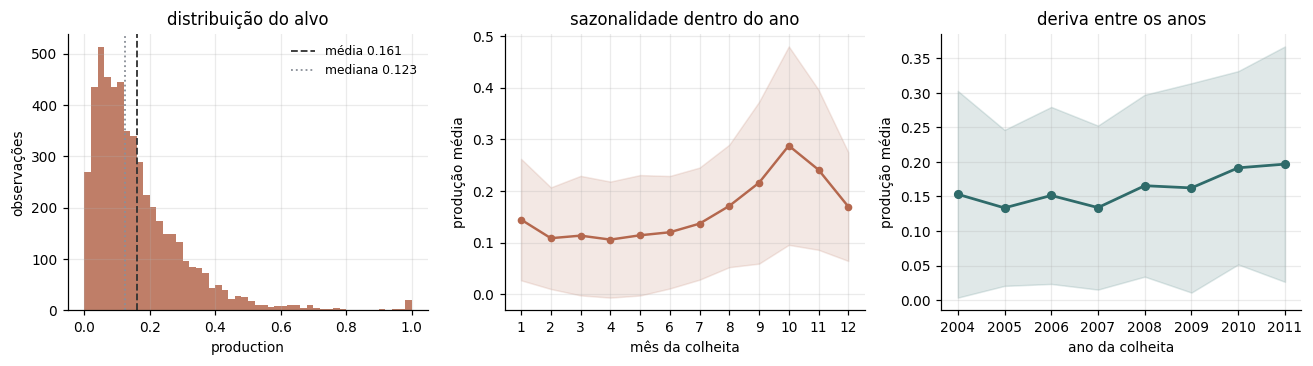

                mean     std
harvest_year                
2004          0.1532  0.1496
2005          0.1335  0.1129
2006          0.1515  0.1281
2007          0.1339  0.1187
2008          0.1656  0.1316
2009          0.1624  0.1515
2010          0.1915  0.1399
2011          0.1968  0.1704

A produção média do último ano é 47% maior que a do ano mais fraco.
Isso é deriva temporal: a relação entre entrada e saída MUDA ao longo do tempo.
É a condição que faltava para o parâmetro q do filtro de Kalman ter função.


In [38]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))

ax[0].hist(y, bins=50, color=COR_REW, alpha=.85)
ax[0].axvline(y.mean(), color="#333", lw=1.2, ls="--", label=f"média {y.mean():.3f}")
ax[0].axvline(y.median(), color=COR_REF, lw=1.2, ls=":", label=f"mediana {y.median():.3f}")
ax[0].set(xlabel="production", ylabel="observações", title="distribuição do alvo")
ax[0].legend(frameon=False, fontsize=8)

mes = train.groupby("harvest_month")["production"].agg(["mean", "std"])
ax[1].plot(mes.index, mes["mean"], marker="o", ms=4, color=COR_REW, lw=1.6)
ax[1].fill_between(mes.index, mes["mean"]-mes["std"], mes["mean"]+mes["std"],
                   color=COR_REW, alpha=.15)
ax[1].set(xlabel="mês da colheita", ylabel="produção média",
          title="sazonalidade dentro do ano", xticks=range(1, 13))

ano = train.groupby("harvest_year")["production"].agg(["mean", "std"])
ax[2].plot(ano.index, ano["mean"], marker="o", ms=5, color=COR_KAL, lw=1.8)
ax[2].fill_between(ano.index, ano["mean"]-ano["std"], ano["mean"]+ano["std"],
                   color=COR_KAL, alpha=.15)
ax[2].set(xlabel="ano da colheita", ylabel="produção média",
          title="deriva entre os anos")

plt.tight_layout(); plt.show()

print(ano.round(4).to_string())
var = (ano["mean"].iloc[-1] / ano["mean"].min() - 1) * 100
print(f"\nA produção média do último ano é {var:.0f}% maior que a do ano mais fraco.")
print("Isso é deriva temporal: a relação entre entrada e saída MUDA ao longo do tempo.")
print("É a condição que faltava para o parâmetro q do filtro de Kalman ter função.")

### Escolhendo o ruído de observação $r$ a partir dos dados

O parâmetro $r$ do filtro é o **ruído de observação**: o quanto cada medição
individual é imprecisa em relação ao valor que se quer estimar. Ele precisa estar
na escala da variância de $y$, senão o filtro fica calibrado errado.

O que uma célula da ReW estima é a produção média das observações que caem
naquele endereço. Então a variância relevante não é a global, é a **variância
dentro dos grupos**. A célula abaixo estima isso agrupando por combinações de
atributos, o que dá uma ordem de grandeza para $r$.

In [39]:
print("VARIÂNCIA DE y, GLOBAL E DENTRO DE GRUPOS\n")
print(f"  variância global                          : {y.var():.5f}   (dp {y.std():.4f})")

for cols in [["harvest_month"], ["field"], ["field", "harvest_month"],
             ["field", "harvest_month", "type"]]:
    g = train.groupby(cols)["production"]
    dentro = g.var().mean()      # variância média dentro dos grupos
    n_gr = g.ngroups
    print(f"  dentro de grupos por {'+'.join(cols):<32}: {dentro:.5f}   "
          f"({n_gr} grupos, {len(train)/n_gr:.0f} obs/grupo)")

r_sugerido = train.groupby(["field", "harvest_month"])["production"].var().mean()
print(f"\n  → r na ordem de {r_sugerido:.4f} (~{r_sugerido:.0e})")
print(f"    usar r=1.0, como fizemos com o House Prices, seria {1.0/r_sugerido:.0f}x")
print(f"    a variância real: o filtro quase não se moveria a cada observação.")

VARIÂNCIA DE y, GLOBAL E DENTRO DE GRUPOS

  variância global                          : 0.01971   (dp 0.1404)
  dentro de grupos por harvest_month                   : 0.01644   (12 grupos, 437 obs/grupo)
  dentro de grupos por field                           : 0.01952   (28 grupos, 187 obs/grupo)
  dentro de grupos por field+harvest_month             : 0.01586   (336 grupos, 16 obs/grupo)
  dentro de grupos por field+harvest_month+type        : 0.01631   (484 grupos, 11 obs/grupo)

  → r na ordem de 0.0159 (~2e-02)
    usar r=1.0, como fizemos com o House Prices, seria 63x
    a variância real: o filtro quase não se moveria a cada observação.


---
## 3. Os modelos

O código é o mesmo dos notebooks anteriores, repetido aqui para o notebook ser
autocontido. Resumo do que cada peça faz:

- **`ThermometerEncoder`** transforma um atributo numérico em bits monotônicos
- **`monta_mapping`** sorteia a permutação fixa da retina e a fatia em RAM nodes
- **`calcula_addresses`** converte cada n-tupla de bits em um inteiro (LSB-first)
- **`RegressionWiSARD`** guarda contador e soma por endereço; prediz $\sum S/\sum c$
- **`KalmanReW`** guarda dois estados de Kalman por endereço; prediz $\sum c_k y_k/\sum c_k$

In [40]:
class ThermometerEncoder:
    def __init__(self, minimum, maximum, resolution):
        self.minimum, self.resolution = minimum, resolution
        self._range = (maximum - minimum) + 1e-9
        self.maximum = maximum

    def encode(self, column):
        col = np.clip(column, self.minimum, self.maximum)
        k = np.clip(((col - self.minimum) / self._range * self.resolution).astype(int),
                    0, self.resolution)
        return (np.arange(self.resolution) < k[:, np.newaxis]).astype(np.uint8)


def build_encoders(X, resolution):
    mins, maxs = X.min(axis=0), X.max(axis=0)
    return [ThermometerEncoder(mins[j], maxs[j], resolution) for j in range(X.shape[1])]


def apply_encoders(X, encoders):
    return np.concatenate([e.encode(X[:, j]) for j, e in enumerate(encoders)], axis=1)


def monta_mapping(retina_size, address_size, rng, completa=True):
    n_rams = retina_size // address_size
    resto = retina_size % address_size
    tamanho = retina_size
    if completa and resto > 0:
        n_rams += 1
        tamanho += address_size - resto
    mapping = list(range(retina_size))
    mapping += [int(rng.integers(0, retina_size)) for _ in range(tamanho - retina_size)]
    rng.shuffle(mapping)
    return np.array(mapping, dtype=int).reshape(n_rams, address_size)


def calcula_addresses(Xb, mapping, address_size):
    pesos = 1 << np.arange(address_size)          # LSB-first, como na referência
    return (Xb[:, mapping] * pesos).sum(axis=2).astype(int)


class SimpleMean:
    def calcula(self, pares):
        sc = sum(c for c, _ in pares); sy = sum(s for _, s in pares)
        return sy / sc if sc > 0 else 0.0

In [41]:
class RegressionWiSARD:
    """Célula = [contador, soma_y]. Predição = Σ soma / Σ contador."""

    def __init__(self, address_size=17, resolution=17, seed=42, mean=None):
        self.address_size, self.resolution = address_size, resolution
        self.mean = mean or SimpleMean()
        self._rng = np.random.default_rng(seed)

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)
        self._encoders = build_encoders(X, self.resolution)
        Xb = apply_encoders(X, self._encoders)
        self.retina_size_ = Xb.shape[1]
        self._mapping = monta_mapping(self.retina_size_, self.address_size, self._rng)
        self.n_rams_ = self._mapping.shape[0]
        addr = calcula_addresses(Xb, self._mapping, self.address_size)

        self._memory = [dict() for _ in range(self.n_rams_)]
        for i in range(len(Xb)):
            for r in range(self.n_rams_):
                a = int(addr[i, r])
                cel = self._memory[r].get(a)
                if cel is None:
                    self._memory[r][a] = [1.0, y[i]]
                else:
                    cel[0] += 1.0; cel[1] += y[i]
        return self

    def predict(self, X):
        Xb = apply_encoders(np.asarray(X, float), self._encoders)
        addr = calcula_addresses(Xb, self._mapping, self.address_size)
        out = np.empty(len(Xb))
        for i in range(len(Xb)):
            pares = []
            for r in range(self.n_rams_):
                cel = self._memory[r].get(int(addr[i, r]))
                pares.append((cel[0], cel[1]) if cel else (0.0, 0.0))
            out[i] = self.mean.calcula(pares)
        return out

    def dont_know(self, X):
        Xb = apply_encoders(np.asarray(X, float), self._encoders)
        addr = calcula_addresses(Xb, self._mapping, self.address_size)
        return np.array([
            np.mean([self._memory[r].get(int(addr[i, r])) is None
                     for r in range(self.n_rams_)]) for i in range(len(Xb))])

In [42]:
class KalmanReW:
    """Célula = [c, y, p_c, p_y], os dois primeiros são estados de Kalman.

        c : observação z = 1.0   → satura em [0,1)  → é o PESO
        y : observação z = y_i   → estima y local   → é a ESTIMATIVA

    Predição:  ŷ = Σ c_k·y_k / Σ c_k

    `ordem_temporal=True` treina na ordem em que os exemplos chegam, sem
    embaralhar. Isso só faz diferença quando q > 0, e é o que permite ao filtro
    reagir a deriva.
    """

    def __init__(self, address_size=17, resolution=17, seed=42,
                 q_c=1e-3, r_c=0.05, q_y=0.0, r_y=0.01, ordem_temporal=False):
        self.address_size, self.resolution = address_size, resolution
        self.q_c, self.r_c, self.q_y, self.r_y = q_c, r_c, q_y, r_y
        self.ordem_temporal = ordem_temporal
        self._rng = np.random.default_rng(seed)

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)
        self._encoders = build_encoders(X, self.resolution)
        Xb = apply_encoders(X, self._encoders)
        self.retina_size_ = Xb.shape[1]
        self._mapping = monta_mapping(self.retina_size_, self.address_size, self._rng)
        self.n_rams_ = self._mapping.shape[0]
        addr = calcula_addresses(Xb, self._mapping, self.address_size)

        ordem = (np.arange(len(Xb)) if self.ordem_temporal
                 else self._rng.permutation(len(Xb)))

        self._memory = [dict() for _ in range(self.n_rams_)]
        for i in ordem:
            for r in range(self.n_rams_):
                a = int(addr[i, r])
                cel = self._memory[r].get(a)
                if cel is None:
                    pc = 1.0 + self.q_c
                    kc = pc / (pc + self.r_c)
                    # estimativa: prior não informativo → aceita o valor de face
                    self._memory[r][a] = [kc, y[i], (1.0 - kc) * pc, self.r_y]
                    continue
                pc = cel[2] + self.q_c                      # atualiza o PESO
                kc = pc / (pc + self.r_c)
                cel[0] += kc * (1.0 - cel[0])
                cel[2] = (1.0 - kc) * pc
                py = cel[3] + self.q_y                      # atualiza a ESTIMATIVA
                ky = py / (py + self.r_y)
                cel[1] += ky * (y[i] - cel[1])
                cel[3] = (1.0 - ky) * py
        return self

    def predict(self, X):
        Xb = apply_encoders(np.asarray(X, float), self._encoders)
        addr = calcula_addresses(Xb, self._mapping, self.address_size)
        out = np.empty(len(Xb))
        for i in range(len(Xb)):
            num = den = 0.0
            for r in range(self.n_rams_):
                cel = self._memory[r].get(int(addr[i, r]))
                if cel is not None:
                    num += cel[0] * cel[1]; den += cel[0]
            out[i] = num / den if den > 0 else 0.0
        return out

In [43]:
def mae(a, b):  return float(np.mean(np.abs(np.asarray(a) - np.asarray(b))))
def rmse(a, b): return float(np.sqrt(np.mean((np.asarray(a) - np.asarray(b))**2)))
def r2(a, b):
    a, b = np.asarray(a, float), np.asarray(b, float)
    return float(1 - np.sum((a-b)**2) / np.sum((a - a.mean())**2))

FEATURES = ["field", "age", "type", "harvest_month"]   # as usadas pelo vencedor
print("atributos:", FEATURES)
print("(a solução vencedora da competição usou exatamente estes quatro,")
print(" sem os dados de solo nem os de clima)")

atributos: ['field', 'age', 'type', 'harvest_month']
(a solução vencedora da competição usou exatamente estes quatro,
 sem os dados de solo nem os de clima)


---
## 4. Protocolo 1: split aleatório

Primeiro o protocolo mais simples, para comparar com o que já fizemos no House
Prices: embaralha tudo, separa 70/30, ignora o tempo.

Aqui o `q` do Kalman continua sem função, porque a ordem de treino é aleatória.

In [44]:
from sklearn.model_selection import train_test_split

def avalia_aleatorio(constroi, seeds=SEEDS):
    acc = []
    for s in seeds:
        tr, te = train_test_split(train, test_size=.30, random_state=s)
        m = constroi(s).fit(tr[FEATURES].values, tr["production"].values)
        yp = m.predict(te[FEATURES].values)
        yt = te["production"].values
        acc.append((mae(yt, yp), rmse(yt, yp), r2(yt, yp)))
    a = np.array(acc)
    return {"MAE": a[:,0].mean(), "MAE_dp": a[:,0].std(),
            "RMSE": a[:,1].mean(), "R2": a[:,2].mean()}

linhas = [
    dict(modelo="chute da mediana", MAE=np.abs(y - y.median()).mean(),
         MAE_dp=0.0, RMSE=np.nan, R2=0.0),
    dict(modelo="ReW", **avalia_aleatorio(
        lambda s: RegressionWiSARD(ADDRESS_SIZE, RESOLUTION, seed=s))),
    dict(modelo="Kalman-ReW", **avalia_aleatorio(
        lambda s: KalmanReW(ADDRESS_SIZE, RESOLUTION, seed=s,
                            q_c=1e-3, r_c=0.05, q_y=0.0, r_y=0.01))),
]
print(pd.DataFrame(linhas).round(5).to_string(index=False))
print(f"\nreferência publicada (ESANN 2019, Public Score): MAE 0.08737")
print(f"referência publicada (tese, Private Score)      : MAE 0.09097")
print("\nAtenção: os números publicados vêm de submissão ao Kaggle, num conjunto")
print("de teste cujos rótulos não são públicos. Aqui o teste sai do arquivo")
print("rotulado, então a comparação é indicativa, não exata.")

          modelo     MAE  MAE_dp    RMSE      R2
chute da mediana 0.09666 0.00000     NaN 0.00000
             ReW 0.07972 0.00211 0.11777 0.29226
      Kalman-ReW 0.07533 0.00223 0.11206 0.35923

referência publicada (ESANN 2019, Public Score): MAE 0.08737
referência publicada (tese, Private Score)      : MAE 0.09097

Atenção: os números publicados vêm de submissão ao Kaggle, num conjunto
de teste cujos rótulos não são públicos. Aqui o teste sai do arquivo
rotulado, então a comparação é indicativa, não exata.


---
## 5. Protocolo 2: validação temporal

Este é o protocolo que a solução vencedora usou, e é o que faz sentido para
dados com ordem temporal: **treinar no passado e prever o futuro**.

Treinamos com todos os anos até $T-1$ e testamos no ano $T$, repetindo para cada
ano disponível. Os exemplos são apresentados ao modelo em **ordem cronológica**,
não embaralhados.

É só neste protocolo que o parâmetro $q$ do filtro tem alguma função: com deriva
no alvo e ordem cronológica no treino, esquecer o passado distante passa a ser
uma decisão com consequência, em vez de ruído.

In [45]:
def avalia_temporal(constroi, seeds=SEEDS):
    """Treina em todos os anos < T, testa no ano T. Ordem cronológica preservada."""
    anos = sorted(train.harvest_year.unique())
    por_ano, acc = {}, []
    for s in seeds:
        for T in anos[2:]:                       # precisa de ao menos 2 anos de treino
            tr = train[train.harvest_year < T].sort_values(["harvest_year", "harvest_month"])
            te = train[train.harvest_year == T]
            m = constroi(s).fit(tr[FEATURES].values, tr["production"].values)
            yp = m.predict(te[FEATURES].values)
            yt = te["production"].values
            e = mae(yt, yp)
            acc.append(e)
            por_ano.setdefault(T, []).append(e)
    return float(np.mean(acc)), float(np.std(acc)), {k: np.mean(v) for k, v in por_ano.items()}


configs = [
    ("ReW",                    lambda s: RegressionWiSARD(ADDRESS_SIZE, RESOLUTION, seed=s)),
    ("Kalman-ReW (q_y=0)",     lambda s: KalmanReW(ADDRESS_SIZE, RESOLUTION, seed=s,
                                    q_c=1e-3, r_c=0.05, q_y=0.0,    r_y=0.01, ordem_temporal=True)),
    ("Kalman-ReW (q_y=1e-4)",  lambda s: KalmanReW(ADDRESS_SIZE, RESOLUTION, seed=s,
                                    q_c=1e-3, r_c=0.05, q_y=1e-4,  r_y=0.01, ordem_temporal=True)),
    ("Kalman-ReW (q_y=1e-3)",  lambda s: KalmanReW(ADDRESS_SIZE, RESOLUTION, seed=s,
                                    q_c=1e-3, r_c=0.05, q_y=1e-3,  r_y=0.01, ordem_temporal=True)),
    ("Kalman-ReW (q_y=1e-2)",  lambda s: KalmanReW(ADDRESS_SIZE, RESOLUTION, seed=s,
                                    q_c=1e-3, r_c=0.05, q_y=1e-2,  r_y=0.01, ordem_temporal=True)),
]

res_temp, curvas = [], {}
for nome, f in configs:
    m_, dp_, por_ano = avalia_temporal(f)
    res_temp.append({"modelo": nome, "MAE": m_, "MAE_dp": dp_})
    curvas[nome] = por_ano
    print(f"  {nome:<26} MAE {m_:.5f}  (dp {dp_:.5f})")

tab_temp = pd.DataFrame(res_temp)

  ReW                        MAE 0.08546  (dp 0.00538)
  Kalman-ReW (q_y=0)         MAE 0.08514  (dp 0.00577)
  Kalman-ReW (q_y=1e-4)      MAE 0.08588  (dp 0.00889)
  Kalman-ReW (q_y=1e-3)      MAE 0.09038  (dp 0.01015)
  Kalman-ReW (q_y=1e-2)      MAE 0.09505  (dp 0.01054)


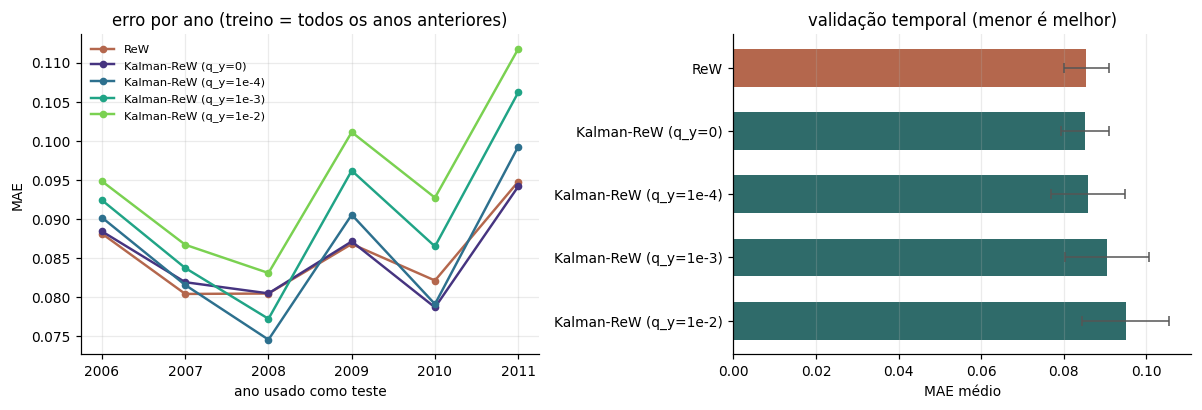

In [46]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))

cores = [COR_REW] + [plt.cm.viridis(v) for v in np.linspace(.15, .8, len(curvas)-1)]
for (nome, por_ano), cor in zip(curvas.items(), cores):
    anos = sorted(por_ano)
    ax[0].plot(anos, [por_ano[a] for a in anos], marker="o", ms=4, lw=1.6,
               color=cor, label=nome)
ax[0].set(xlabel="ano usado como teste", ylabel="MAE",
          title="erro por ano (treino = todos os anos anteriores)")
ax[0].legend(frameon=False, fontsize=7.5)

ypos = np.arange(len(tab_temp))[::-1]
cores_bar = [COR_REW] + [COR_KAL]*(len(tab_temp)-1)
ax[1].barh(ypos, tab_temp["MAE"], xerr=tab_temp["MAE_dp"], color=cores_bar,
           height=.6, error_kw=dict(lw=1, capsize=3, ecolor="#555"))
ax[1].set(yticks=ypos, yticklabels=tab_temp["modelo"], xlabel="MAE médio",
          title="validação temporal (menor é melhor)")
ax[1].grid(axis="y", visible=False)

plt.tight_layout(); plt.show()

---
## 6. Os dois protocolos lado a lado

A tabela abaixo junta tudo. A leitura que importa é **como a diferença entre ReW
e Kalman-ReW muda** de um protocolo para o outro.

                protocolo     ReW  Kalman-ReW   ganho
    aleatório (sem tempo) 0.07972     0.07533 5.50877
temporal (passado→futuro) 0.08546     0.08514 0.37451

melhor configuração no protocolo temporal: Kalman-ReW (q_y=0)


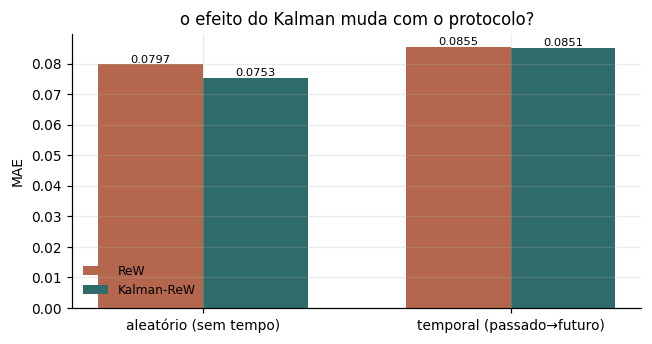

In [47]:
alea_rew = avalia_aleatorio(lambda s: RegressionWiSARD(ADDRESS_SIZE, RESOLUTION, seed=s))
alea_kal = avalia_aleatorio(lambda s: KalmanReW(ADDRESS_SIZE, RESOLUTION, seed=s,
                                q_c=1e-3, r_c=0.05, q_y=0.0, r_y=0.01))

melhor_kal = tab_temp.iloc[tab_temp["MAE"].values.argmin()]
rew_temp = tab_temp[tab_temp.modelo == "ReW"].iloc[0]

resumo = pd.DataFrame([
    {"protocolo": "aleatório (sem tempo)", "ReW": alea_rew["MAE"], "Kalman-ReW": alea_kal["MAE"]},
    {"protocolo": "temporal (passado→futuro)", "ReW": rew_temp["MAE"], "Kalman-ReW": melhor_kal["MAE"]},
])
resumo["ganho"] = (1 - resumo["Kalman-ReW"] / resumo["ReW"]) * 100
print(resumo.round(5).to_string(index=False))
print(f"\nmelhor configuração no protocolo temporal: {melhor_kal['modelo']}")

fig, ax = plt.subplots(figsize=(6, 3.2))
x = np.arange(2); w = .34
ax.bar(x - w/2, resumo["ReW"], w, color=COR_REW, label="ReW")
ax.bar(x + w/2, resumo["Kalman-ReW"], w, color=COR_KAL, label="Kalman-ReW")
ax.set(xticks=x, xticklabels=resumo["protocolo"], ylabel="MAE",
       title="o efeito do Kalman muda com o protocolo?")
ax.legend(frameon=False, fontsize=8)
for i, (a, b) in enumerate(zip(resumo["ReW"], resumo["Kalman-ReW"])):
    ax.text(i - w/2, a, f"{a:.4f}", ha="center", va="bottom", fontsize=7.5)
    ax.text(i + w/2, b, f"{b:.4f}", ha="center", va="bottom", fontsize=7.5)
plt.tight_layout(); plt.show()

---
## 7. O que registrar

Preencha depois de rodar, com os números que aparecerem:

**A implementação bate com o publicado?** O MAE da ReW deve ficar na vizinhança
de 0.087 a 0.091. Se estiver muito longe, provavelmente falta o pré-processamento
que a tese descreve (janela de clima e atributos de solo), que não está nos
arquivos públicos.

**O peso saturado ajuda aqui também?** No House Prices ajudou muito, mas o
mecanismo era compressão por blocos gigantes. Com só quatro atributos e uma
retina bem menor, os blocos são outros, e o efeito pode não se repetir.

**O `q_y` ajuda no protocolo temporal?** Esta é a pergunta que os experimentos
anteriores não conseguiram responder, porque o House Prices não tinha eixo
temporal. Aqui existe deriva medida, então há o que testar. Duas leituras
possíveis:

- se o MAE melhorar com `q_y > 0`, o esquecimento tem função e o filtro está
  fazendo algo que a ReW não faz
- se piorar, a deriva entre anos não é forte o bastante para compensar a perda
  de evidência acumulada, e vale medir o quanto ela precisaria ser

**Uma limitação a registrar de qualquer forma.** O teste do Kaggle não tem
rótulo público, então nenhum número aqui é diretamente comparável ao da tese. A
comparação é de ordem de grandeza.